In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="darkgrid")

In [2]:
df = pd.read_csv(
    "../data/processed/HR_Employee_Attrition_Cleaned.csv"
)

print("Dataset Loaded Successfully!")

df.head()

Dataset Loaded Successfully!


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (1470, 35)

Column Names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   Busin

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


In [10]:
total_employees = len(df)

attrition_count = (
    df["Attrition"].astype(str).str.strip().str.lower() == "yes"
).sum()

active_employees = total_employees - attrition_count

attrition_rate = (
    attrition_count / total_employees * 100
    if total_employees else 0
)

average_age = df["Age"].mean()

average_monthly_income = df["MonthlyIncome"].mean()

average_years_at_company = df["YearsAtCompany"].mean()

print("========== HR ANALYTICS KPIs ==========")

print("Total Employees:", total_employees)
print("Employees Left:", attrition_count)
print("Active Employees:", active_employees)

print("Attrition Rate:", round(attrition_rate, 2), "%")

print("Average Employee Age:", round(average_age, 2))

print("Average Monthly Income:",
      round(average_monthly_income, 2))

print("Average Years at Company:",
      round(average_years_at_company, 2))

========== HR ANALYTICS KPIs ==========
Total Employees: 1470
Employees Left: 237
Active Employees: 1233
Attrition Rate: 16.12 %
Average Employee Age: 36.92
Average Monthly Income: 6502.93
Average Years at Company: 7.01


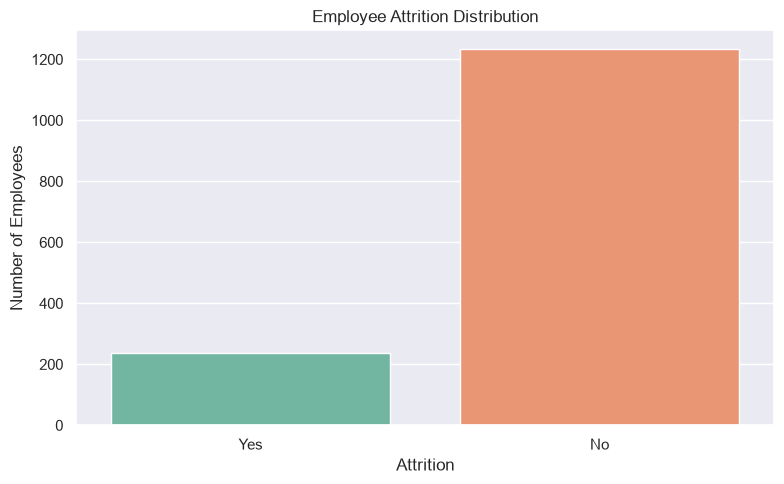

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Attrition",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

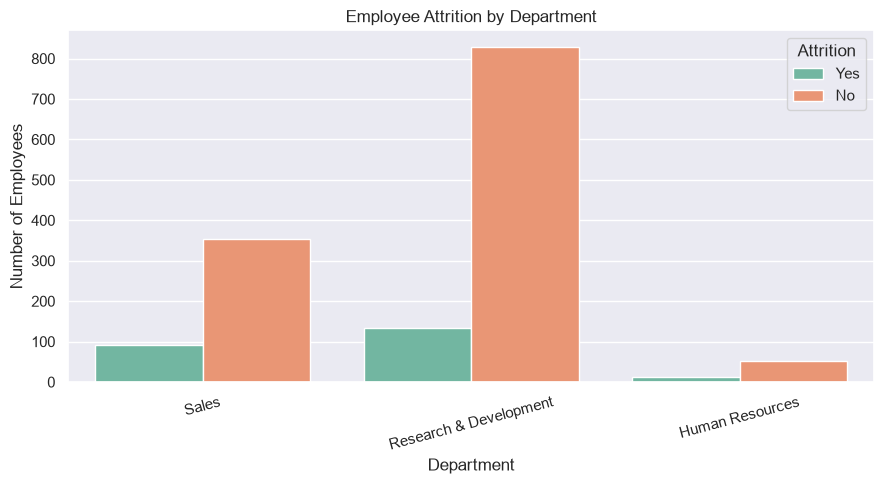

In [6]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Department",
    hue="Attrition",
    palette="Set2"
)

plt.title("Employee Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

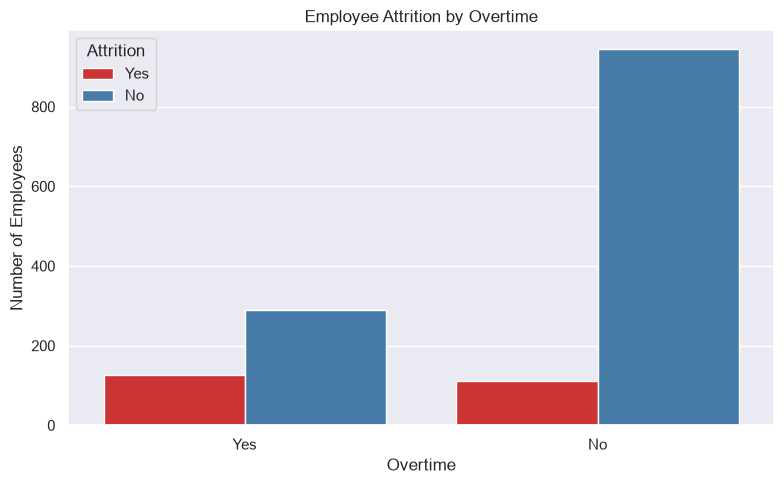

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="OverTime",
    hue="Attrition",
    palette="Set1"
)

plt.title("Employee Attrition by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

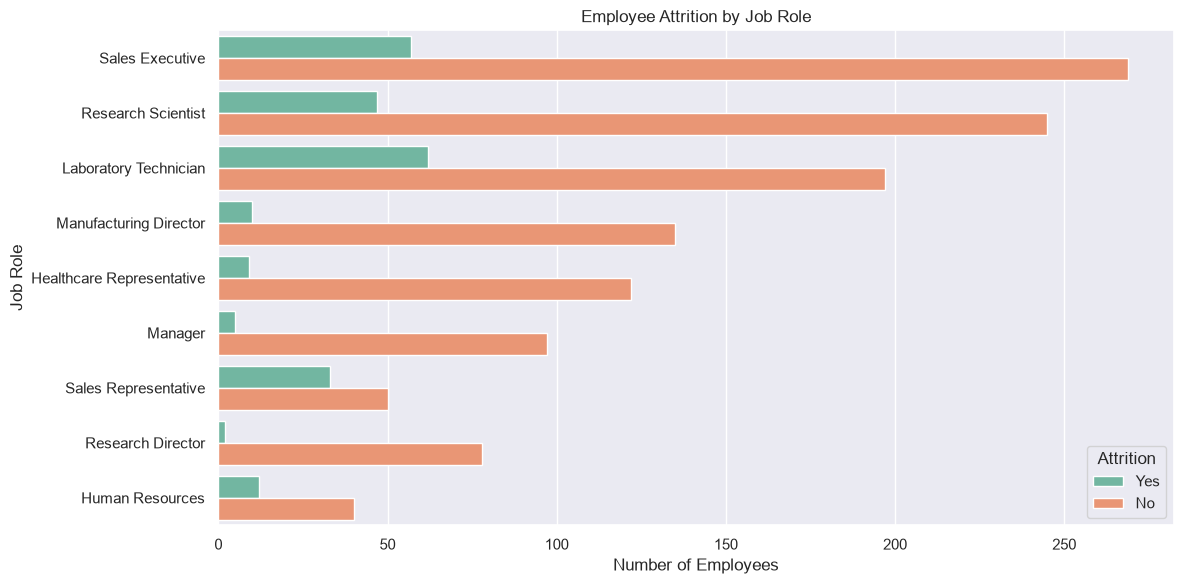

In [8]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="JobRole",
    hue="Attrition",
    palette="Set2"
)

plt.title("Employee Attrition by Job Role")
plt.xlabel("Number of Employees")
plt.ylabel("Job Role")

plt.tight_layout()
plt.show()

Department
Sales                     20.63
Human Resources           19.05
Research & Development    13.84
Name: Attrition, dtype: float64


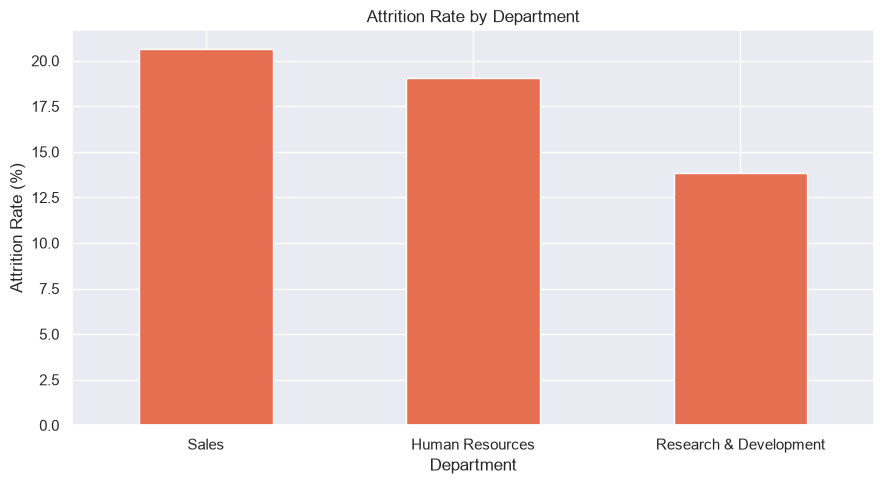

In [12]:
department_rate = (
    df.groupby("Department")["Attrition"]
    .apply(
        lambda x: (
            x.astype(str).str.strip().str.lower() == "yes"
        ).mean() * 100
    )
    .sort_values(ascending=False)
)

print(department_rate.round(2))

department_rate.plot(
    kind="bar",
    figsize=(9, 5),
    color="#E76F51"
)

plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

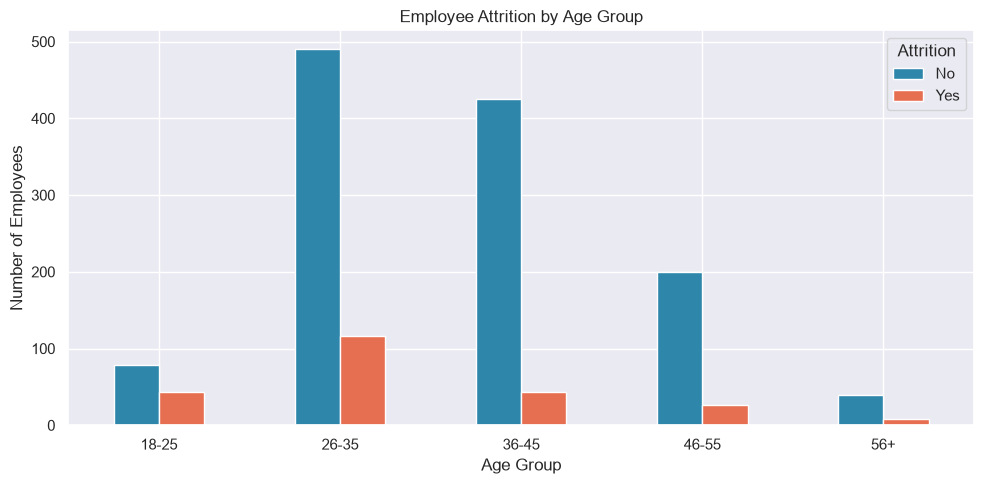

In [13]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56+"
    ]
)

age_attrition = pd.crosstab(
    df["AgeGroup"],
    df["Attrition"]
)

age_attrition.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2E86AB", "#E76F51"]
)

plt.title("Employee Attrition by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Attrition     No    Yes
OverTime               
No         89.56  10.44
Yes        69.47  30.53


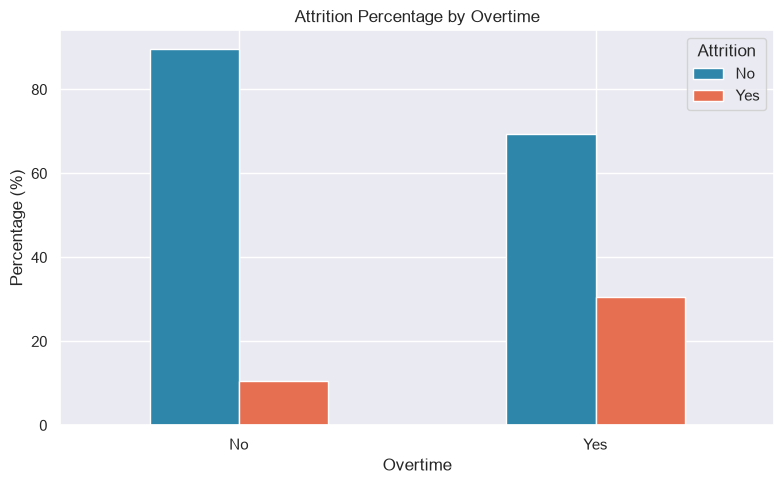

In [14]:
overtime_attrition = pd.crosstab(
    df["OverTime"],
    df["Attrition"],
    normalize="index"
) * 100

print(overtime_attrition.round(2))

overtime_attrition.plot(
    kind="bar",
    figsize=(8, 5),
    color=["#2E86AB", "#E76F51"]
)

plt.title("Attrition Percentage by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

JobRole
Sales Representative         39.76
Laboratory Technician        23.94
Human Resources              23.08
Sales Executive              17.48
Research Scientist           16.10
Manufacturing Director        6.90
Healthcare Representative     6.87
Manager                       4.90
Research Director             2.50
Name: Attrition, dtype: float64


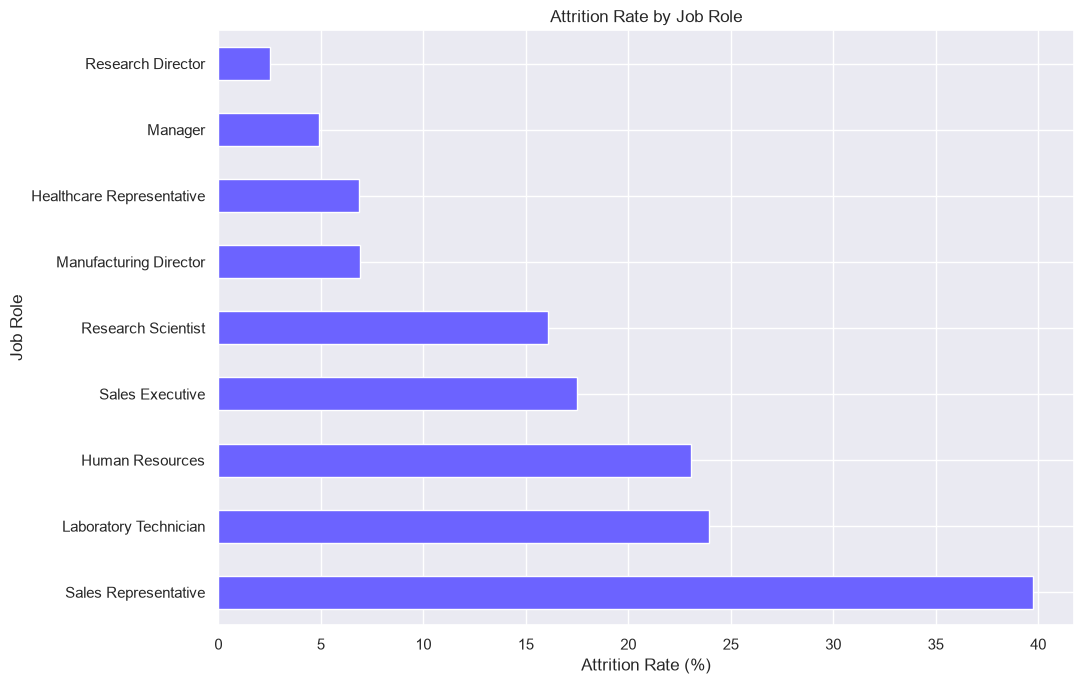

In [15]:
jobrole_attrition = (
    df.groupby("JobRole")["Attrition"]
    .apply(
        lambda x: (
            x.astype(str).str.strip().str.lower() == "yes"
        ).mean() * 100
    )
    .sort_values(ascending=False)
)

print(jobrole_attrition.round(2))

jobrole_attrition.plot(
    kind="barh",
    figsize=(11, 7),
    color="#6C63FF"
)

plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")

plt.tight_layout()
plt.show()

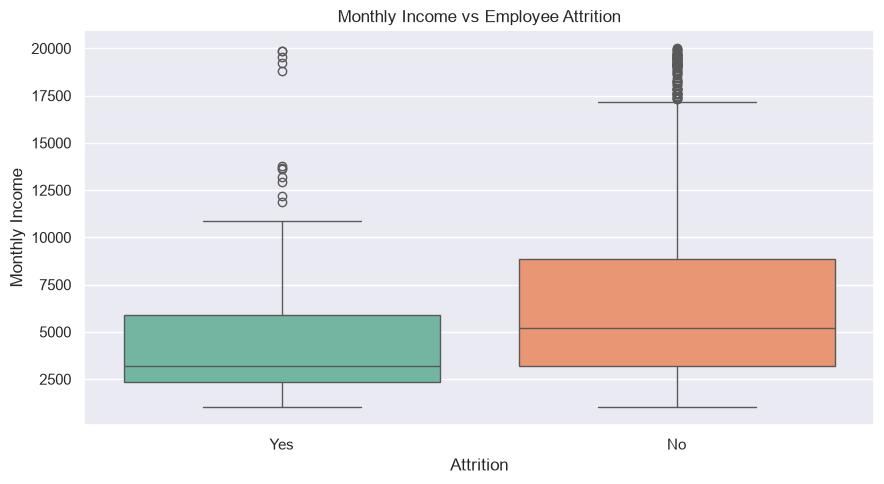

In [16]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Monthly Income vs Employee Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.show()

Attrition           No    Yes
JobSatisfaction              
1                77.16  22.84
2                83.57  16.43
3                83.48  16.52
4                88.67  11.33


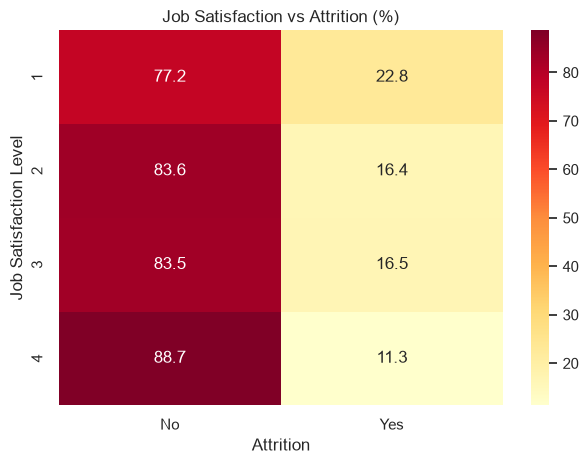

In [17]:
satisfaction_attrition = pd.crosstab(
    df["JobSatisfaction"],
    df["Attrition"],
    normalize="index"
) * 100

print(satisfaction_attrition.round(2))

sns.heatmap(
    satisfaction_attrition,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Job Satisfaction vs Attrition (%)")
plt.xlabel("Attrition")
plt.ylabel("Job Satisfaction Level")

plt.tight_layout()
plt.show()

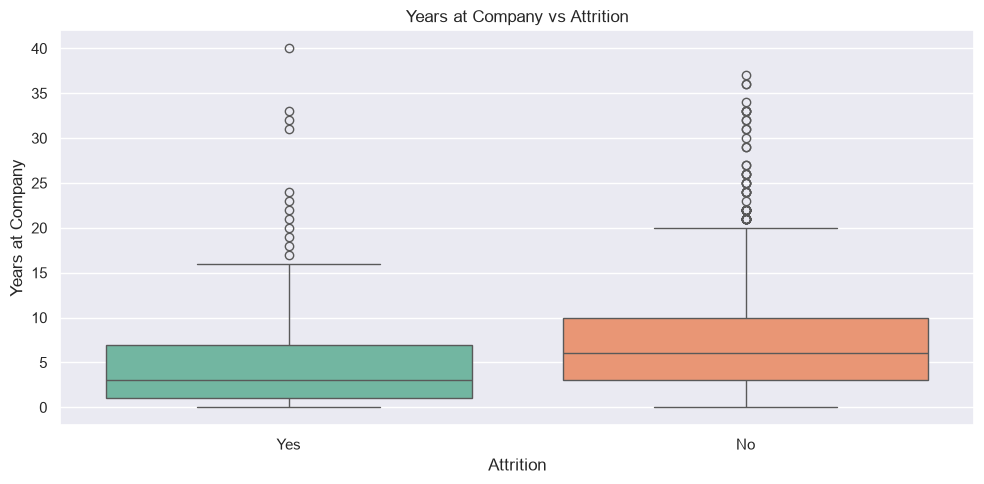

In [18]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="Attrition",
    y="YearsAtCompany",
    hue="Attrition",
    palette="Set2",
    legend=False
)

plt.title("Years at Company vs Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.tight_layout()
plt.show()

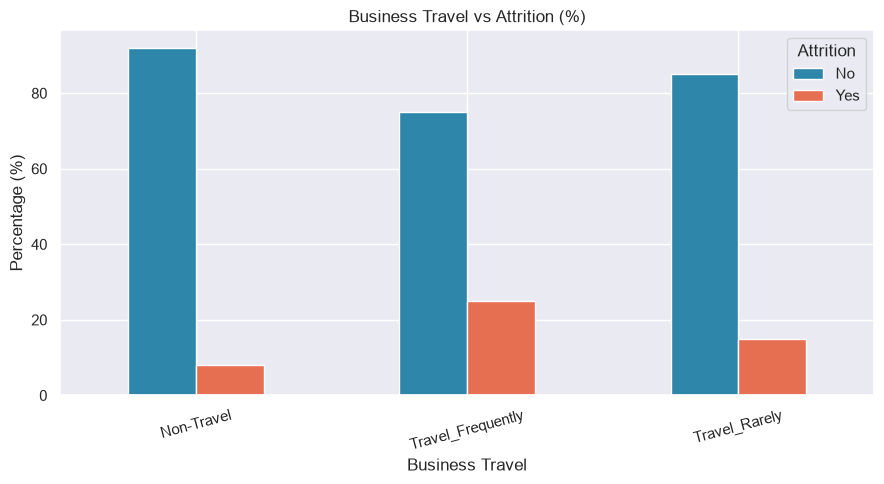

In [ ]:
travel_attrition = pd.crosstab(
    df["BusinessTravel"],
    df["Attrition"],
    normalize="index"
) * 100

travel_attrition.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#2E86AB", "#E76F51"]
)

plt.title("Business Travel vs Attrition (%)")
plt.xlabel("Business Travel")
plt.ylabel("Percentage (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

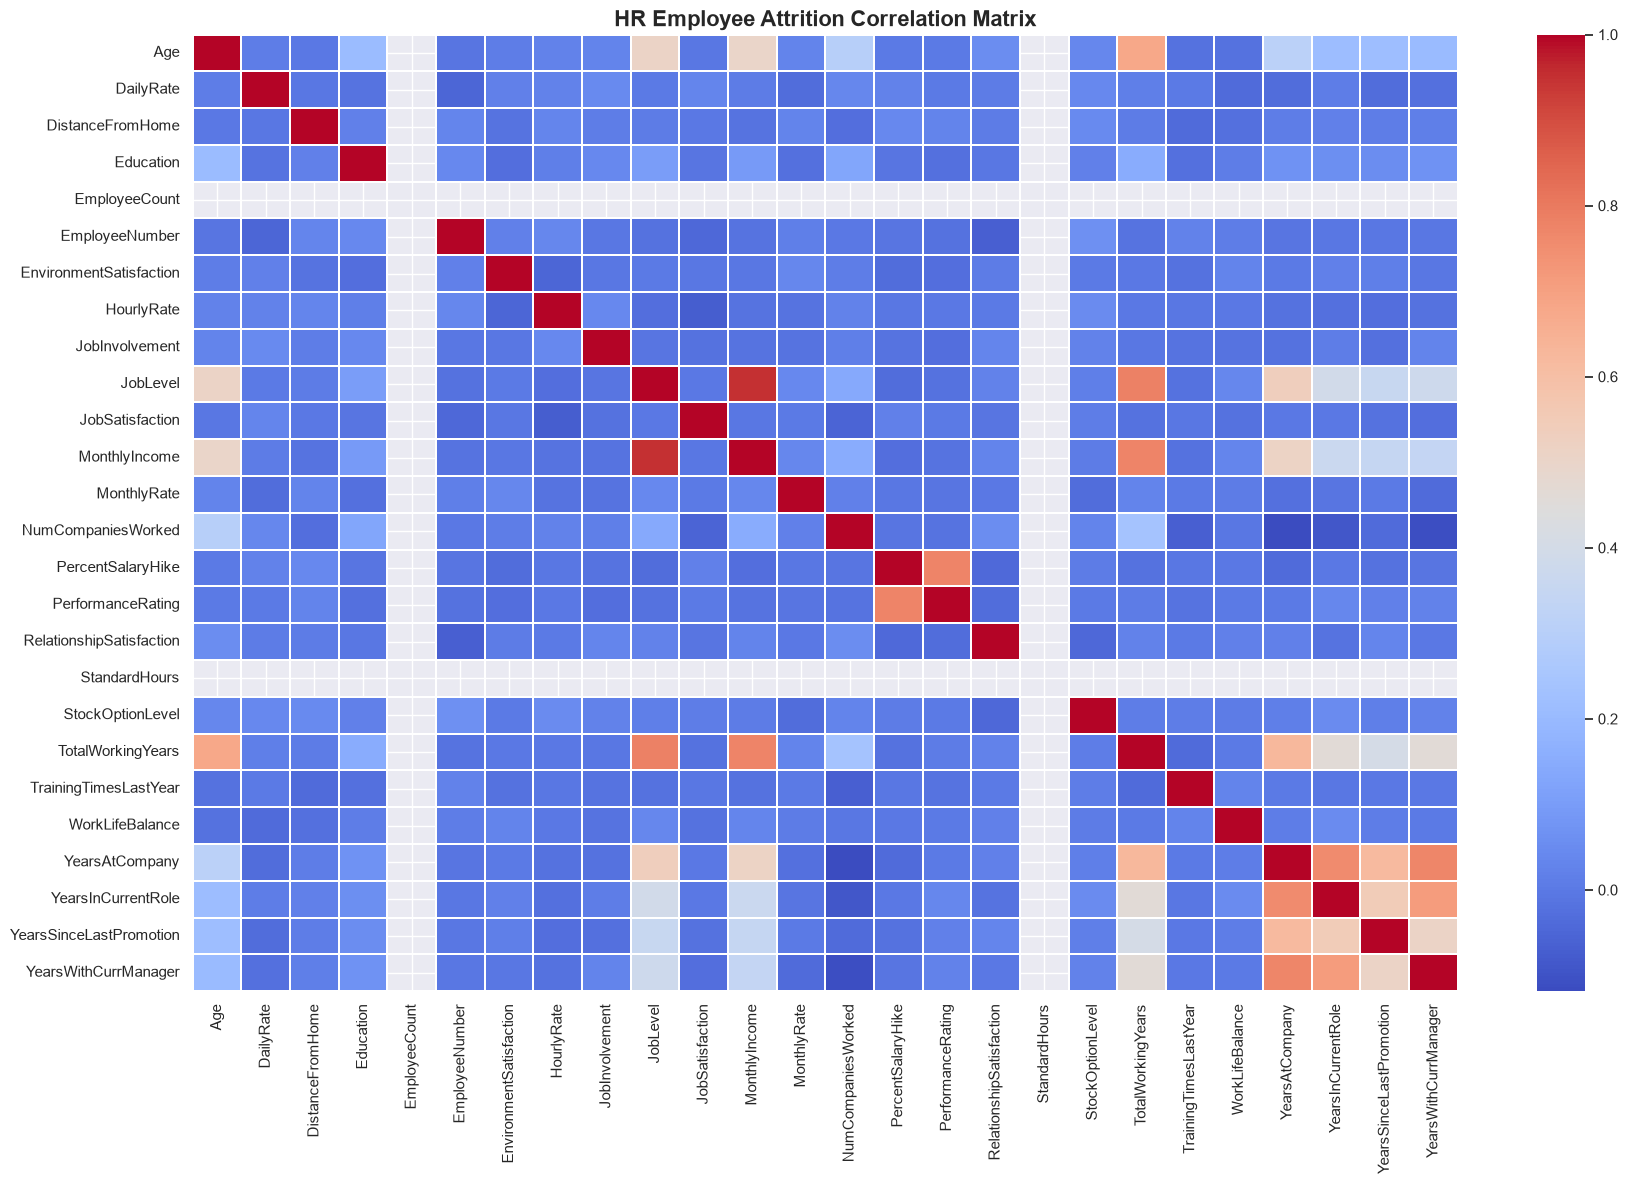

In [20]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(18, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False,
    linewidths=0.3
)

plt.title("HR Employee Attrition Correlation Matrix",
          fontsize=16, fontweight="bold")

plt.tight_layout()
plt.show()

DistanceFromHome            0.078
NumCompaniesWorked          0.043
MonthlyRate                 0.015
PerformanceRating           0.003
HourlyRate                 -0.007
EmployeeNumber             -0.011
PercentSalaryHike          -0.013
Education                  -0.031
YearsSinceLastPromotion    -0.033
RelationshipSatisfaction   -0.046
DailyRate                  -0.057
TrainingTimesLastYear      -0.059
WorkLifeBalance            -0.064
EnvironmentSatisfaction    -0.103
JobSatisfaction            -0.103
JobInvolvement             -0.130
YearsAtCompany             -0.134
StockOptionLevel           -0.137
YearsWithCurrManager       -0.156
Age                        -0.159
MonthlyIncome              -0.160
YearsInCurrentRole         -0.161
JobLevel                   -0.169
TotalWorkingYears          -0.171
EmployeeCount                 NaN
StandardHours                 NaN
Name: AttritionNumeric, dtype: float64


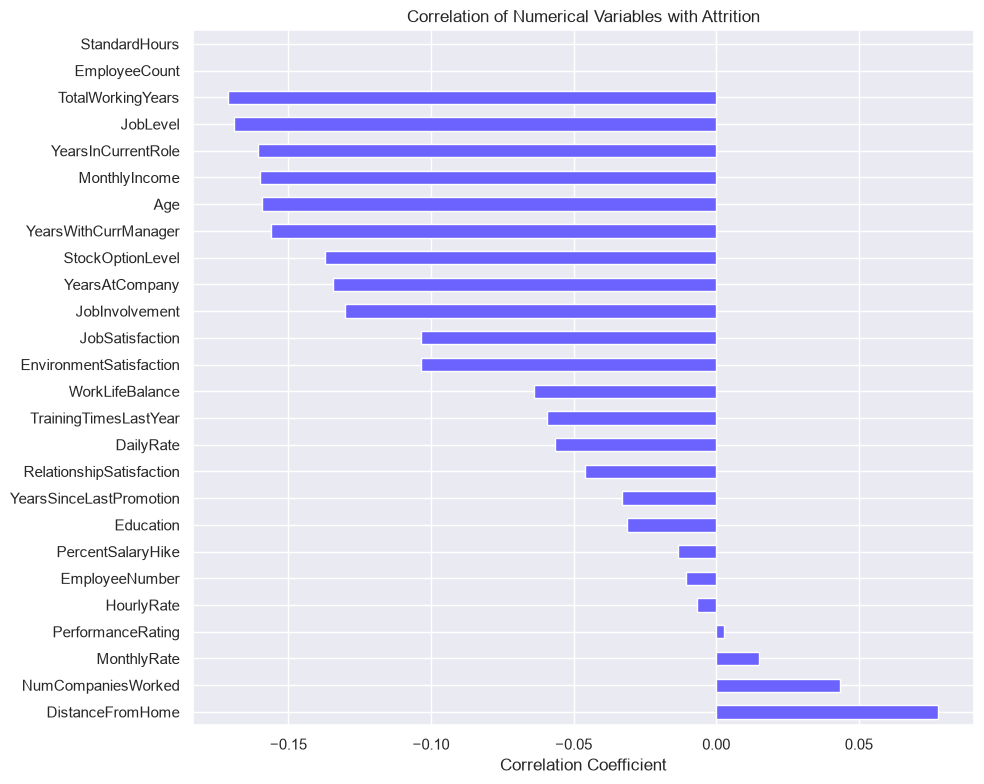

In [21]:
df["AttritionNumeric"] = (
    df["Attrition"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

attrition_correlation = (
    df.select_dtypes(include="number")
    .corr()["AttritionNumeric"]
    .drop("AttritionNumeric")
    .sort_values(ascending=False)
)

print(attrition_correlation.round(3))

attrition_correlation.plot(
    kind="barh",
    figsize=(10, 8),
    color="#6C63FF"
)

plt.title("Correlation of Numerical Variables with Attrition")
plt.xlabel("Correlation Coefficient")

plt.tight_layout()
plt.show()

In [22]:
summary = pd.DataFrame({
    "Metric": [
        "Total Employees",
        "Employees Left",
        "Active Employees",
        "Attrition Rate",
        "Average Age",
        "Average Monthly Income",
        "Average Years at Company"
    ],
    "Value": [
        total_employees,
        attrition_count,
        active_employees,
        round(attrition_rate, 2),
        round(average_age, 2),
        round(average_monthly_income, 2),
        round(average_years_at_company, 2)
    ]
})

display(summary)

,Metric,Value
0,Total Employees,1470.00
1,Employees Left,237.00
2,Active Employees,1233.00
3,Attrition Rate,16.12
4,Average Age,36.92
5,Average Monthly Income,6502.93
6,Average Years at Company,7.01


,WorkLifeBalance,WorkLifeBalance_Label,Total_Employees,Attrition_Count,Attrition_Rate
0,1,Bad,80,25,31.250000
1,2,Good,344,58,16.860465
2,3,Better,893,127,14.221725
3,4,Best,153,27,17.647059


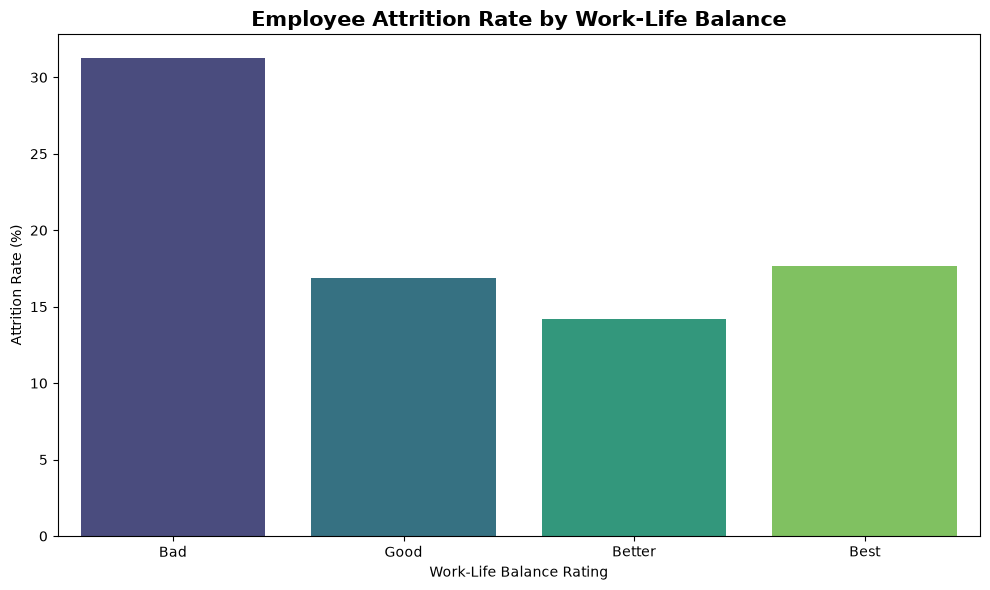

In [5]:
import pandas as pd
import seaborn as sns


# ==========================================
# 13. WORK-LIFE BALANCE VS ATTRITION
# ==========================================

# Work-Life Balance rating labels
wlb_labels = {
    1: "Bad",
    2: "Good",
    3: "Better",
    4: "Best"
}

# Create a readable column
if "df" not in globals():

    df = pd.read_csv(
        "../data/processed/HR_Employee_Attrition_Cleaned.csv"
    )

df["WorkLifeBalance_Label"] = df["WorkLifeBalance"].map(wlb_labels)

# Calculate employee count and attrition count
wlb_analysis = df.groupby(
    ["WorkLifeBalance", "WorkLifeBalance_Label"],
    observed=True
).agg(
    Total_Employees=("Attrition", "count"),
    Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
).reset_index()

# Calculate attrition rate
wlb_analysis["Attrition_Rate"] = (
    wlb_analysis["Attrition_Count"] /
    wlb_analysis["Total_Employees"] * 100
)

display(wlb_analysis)

# Visualization
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.barplot(
    data=wlb_analysis,
    x="WorkLifeBalance_Label",
    y="Attrition_Rate",
    hue="WorkLifeBalance_Label",
    palette="viridis",
    legend=False
)

plt.title(
    "Employee Attrition Rate by Work-Life Balance",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Work-Life Balance Rating")
plt.ylabel("Attrition Rate (%)")

plt.tight_layout()
plt.show()


,YearsSinceLastPromotion,Total_Employees,Attrition_Count,Attrition_Rate
0,0,581,110,18.932874
1,1,357,49,13.725490
2,2,159,27,16.981132
3,3,52,9,17.307692
4,4,61,5,8.196721
5,5,45,2,4.444444
6,6,32,6,18.750000
7,7,76,16,21.052632
8,8,18,0,0.000000
9,9,17,4,23.529412


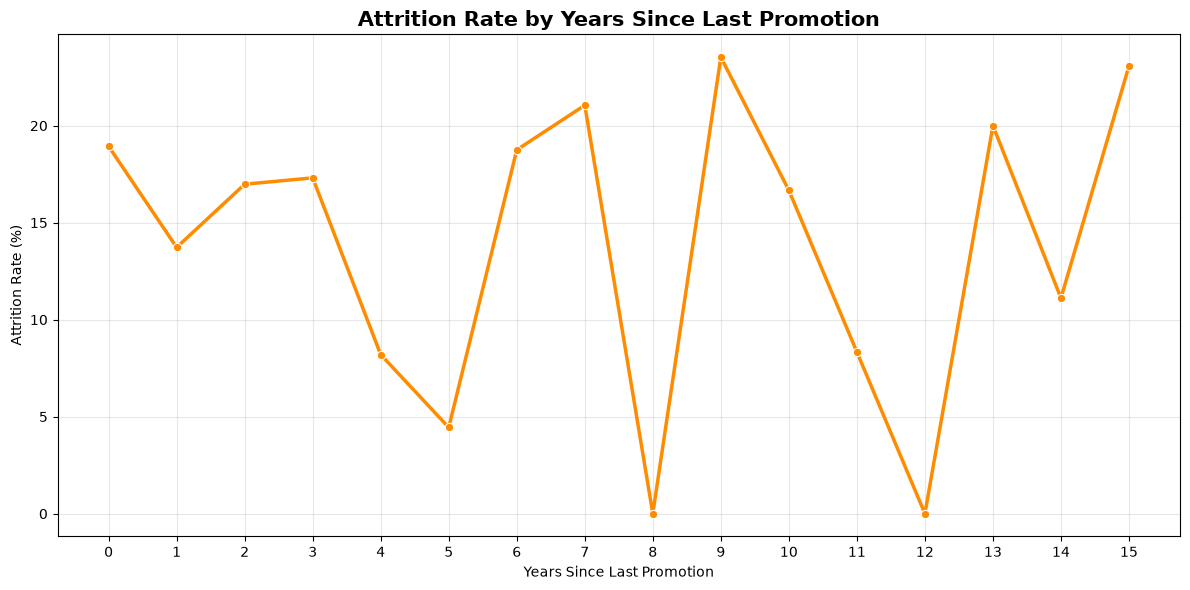

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# ==========================================
# 14. YEARS SINCE LAST PROMOTION VS ATTRITION
# ==========================================

# Group employees based on years since last promotion

promotion_analysis = df.groupby(
    "YearsSinceLastPromotion"
).agg(
    Total_Employees=("Attrition", "count"),
    Attrition_Count=("Attrition", lambda x: (x == "Yes").sum())
).reset_index()

# Calculate attrition rate

promotion_analysis["Attrition_Rate"] = (
    promotion_analysis["Attrition_Count"] /
    promotion_analysis["Total_Employees"] * 100
)

display(promotion_analysis)

# Visualization

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=promotion_analysis,
    x="YearsSinceLastPromotion",
    y="Attrition_Rate",
    marker="o",
    linewidth=2.5,
    color="darkorange"
)

plt.title(
    "Attrition Rate by Years Since Last Promotion",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Years Since Last Promotion")
plt.ylabel("Attrition Rate (%)")

plt.xticks(
    sorted(df["YearsSinceLastPromotion"].dropna().unique())
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Salary Summary by Attrition:


,Attrition,count,mean,median,min,max
0,No,1233,6832.739659,5204.0,1051,19999
1,Yes,237,4787.092827,3202.0,1009,19859


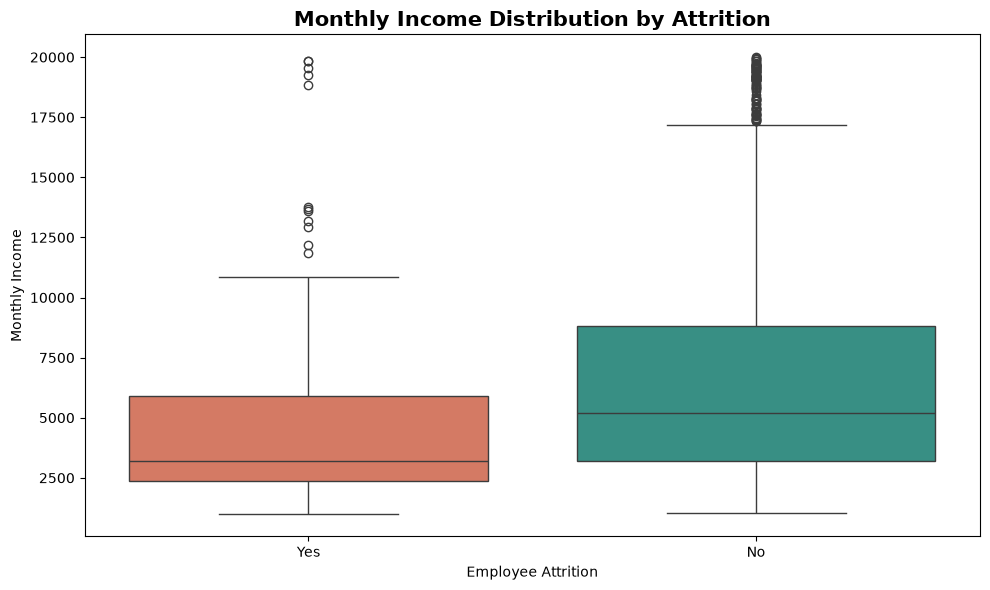

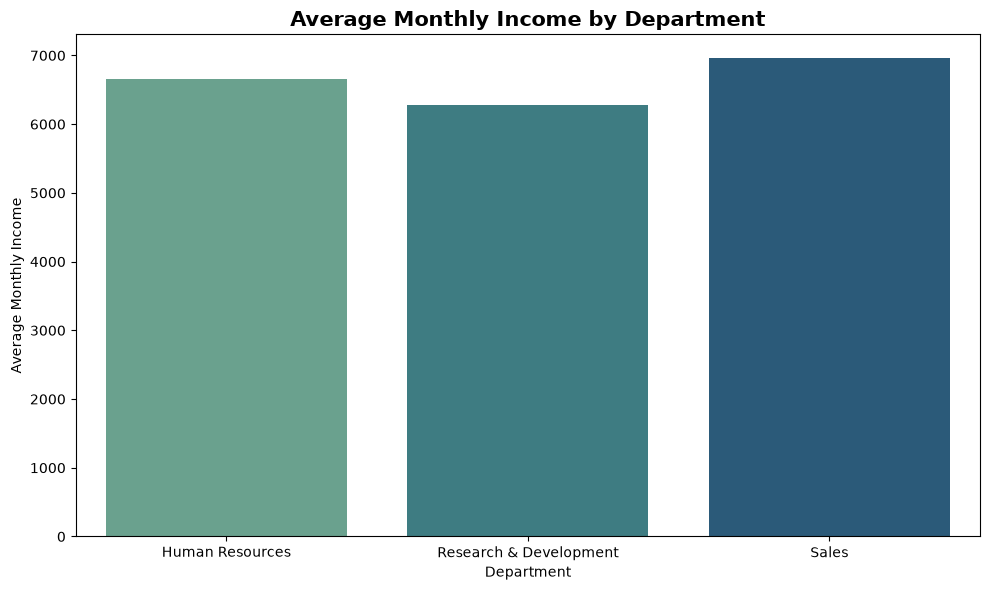

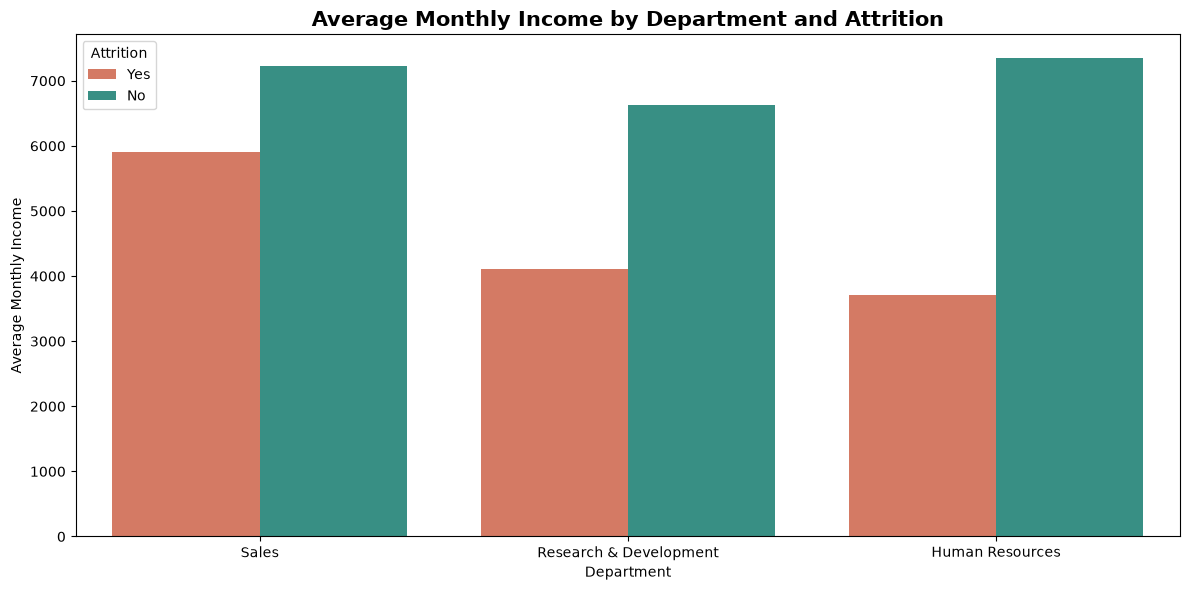

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# ==========================================
# 15. SALARY DISTRIBUTION ANALYSIS
# ==========================================

# Summary statistics by attrition status

salary_summary = df.groupby("Attrition")[
    "MonthlyIncome"
].agg(
    ["count", "mean", "median", "min", "max"]
).reset_index()

print("Salary Summary by Attrition:")
display(salary_summary)

# Visualization 1: Salary distribution

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Attrition",
    y="MonthlyIncome",
    hue="Attrition",
    palette={
        "Yes": "#E76F51",
        "No": "#2A9D8F"
    },
    legend=False
)

plt.title(
    "Monthly Income Distribution by Attrition",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Employee Attrition")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.show()


# Visualization 2: Average salary by department

department_salary = df.groupby(
    "Department"
)["MonthlyIncome"].mean().reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=department_salary,
    x="Department",
    y="MonthlyIncome",
    hue="Department",
    palette="crest",
    legend=False
)

plt.title(
    "Average Monthly Income by Department",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Department")
plt.ylabel("Average Monthly Income")

plt.tight_layout()
plt.show()


# Visualization 3: Average income by department and attrition

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df,
    x="Department",
    y="MonthlyIncome",
    hue="Attrition",
    estimator="mean",
    errorbar=None,
    palette={
        "Yes": "#E76F51",
        "No": "#2A9D8F"
    }
)

plt.title(
    "Average Monthly Income by Department and Attrition",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Department")
plt.ylabel("Average Monthly Income")

plt.tight_layout()
plt.show()
